# 04 · Séries temporais: sazonalidade, anomalias e lacunas

**AgroGeo Analytics · Projeto 01**

> ⚠️ Série **sintética**. Dois eventos foram *injetados de propósito* pelo gerador para permitir testar os métodos com "gabarito": **T03** (queda tipo poda/esqueletamento a partir de 10/08/2023, recuperação gradual) e **T08** (nível reduzido de forma persistente a partir de 01/03/2023). Isto **não** é um achado empírico.

## Objetivos
1. Diagnosticar **lacunas** nas séries.
2. Estimar **sazonalidade** (climatologia mensal).
3. Calcular **anomalia temporal** (contra a climatologia do próprio talhão) e **anomalia relativa** (contra os vizinhos).
4. Marcar anomalias e verificar contra o gabarito sintético.

In [1]:
import sys
from pathlib import Path
try:
    import agrogeo  # noqa: F401  (pacote instalado com `pip install -e .`)
except ModuleNotFoundError:  # kernel sem o pacote: usa o código-fonte do repositório
    _src = next(p / "src" for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "agrogeo").is_dir())
    sys.path.insert(0, str(_src))

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

from agrogeo import config, gis, indices, zonal, timeseries as ts_lib, maps
from agrogeo.config import DATA_SAMPLE, OUTPUTS, CRS_GEO, CRS_UTM22S

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25,
                     "axes.spines.top": False, "axes.spines.right": False})
(OUTPUTS / "figures").mkdir(parents=True, exist_ok=True)
SYNTH_NOTE = "DADOS SINTÉTICOS — ilustrativo, não é medição"
serie = pd.read_csv(DATA_SAMPLE / "serie_sintetica_ndvi_ndre.csv", parse_dates=["date"])
BASE = ("2021-01-01", "2022-12-31")   # período-base: anterior aos eventos injetados
print(serie.shape, serie["date"].min().date(), "→", serie["date"].max().date())

(3516, 6) 2021-01-01 → 2024-12-31


## 1. Lacunas

Uma **lacuna** é um intervalo entre duas observações válidas consecutivas maior que um limite (aqui 20 dias; o Sentinel-2 revisita a cada ~5 dias, então 20 dias = ~4 passagens perdidas).

In [2]:
gs = ts_lib.gap_summary(serie, "ndvi", min_days=20)
print(gs.describe().loc[["mean", "min", "max"]].round(1))
gaps_t01 = ts_lib.find_gaps(serie.loc[serie.talhao_id == "T01", "date"], serie.loc[serie.talhao_id == "T01", "ndvi"], 20)
gaps_t01.sort_values("dias", ascending=False).head()

      n_lacunas  maior_lacuna_dias
mean        5.0               44.2
min         1.0               30.0
max         9.0               70.0


,inicio,fim,dias
1,2022-12-12,2023-01-26,45
0,2021-11-22,2022-01-01,40
2,2023-11-27,2023-12-27,30
3,2024-11-06,2024-12-06,30


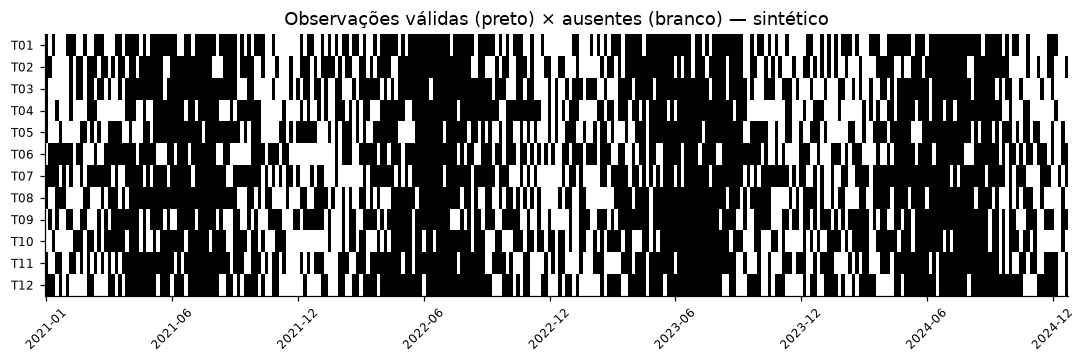

In [3]:
piv = serie.assign(ok=serie["ndvi"].notna().astype(int)).pivot(index="talhao_id", columns="date", values="ok")
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.imshow(piv.values, aspect="auto", cmap="Greys", interpolation="nearest")
ticks = np.arange(0, piv.shape[1], 36); ax.set_xticks(ticks); ax.set_xticklabels([piv.columns[i].strftime("%Y-%m") for i in ticks], rotation=45, fontsize=8)
ax.set_yticks(range(len(piv))); ax.set_yticklabels(piv.index, fontsize=8); ax.grid(False)
ax.set_title("Observações válidas (preto) × ausentes (branco) — sintético")
plt.tight_layout(); plt.savefig(OUTPUTS / "figures" / "04_lacunas.png"); plt.show()

**Como ler:** colunas brancas em várias linhas = datas sem dado em todos (nuvem regional). Faixas brancas largas aparecem no verão. Séries com muitas lacunas exigem cuidado: **a ausência de dado não é ausência de problema**.

## 2. Interpolação limitada e suavização

Para visualização, preenchemos lacunas **curtas** (≤ 30 dias) por interpolação linear no tempo e suavizamos com média móvel. Lacunas maiores permanecem vazias (não inventamos dados).

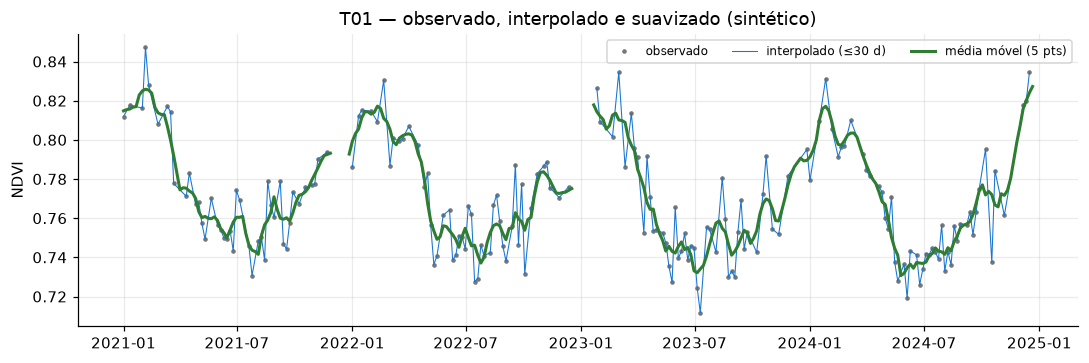

Pontos preenchidos: 91 | ainda ausentes: 18


In [4]:
s = serie[serie.talhao_id == "T01"].set_index("date")["ndvi"]
s_i = ts_lib.interpolate_series(s, max_gap_days=30)
s_s = ts_lib.rolling_smooth(s_i, window=5)
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(s.index, s, ".", color="#777", ms=4, label="observado")
ax.plot(s_i.index, s_i, "-", lw=.7, color="#1976d2", label="interpolado (≤30 d)")
ax.plot(s_s.index, s_s, "-", lw=2, color="#2e7d32", label="média móvel (5 pts)")
ax.set(ylabel="NDVI", title="T01 — observado, interpolado e suavizado (sintético)"); ax.legend(ncol=3, fontsize=8)
plt.tight_layout(); plt.savefig(OUTPUTS / "figures" / "04_interpolacao.png"); plt.show()
print("Pontos preenchidos:", int(s_i.notna().sum() - s.notna().sum()), "| ainda ausentes:", int(s_i.isna().sum()))

**Como ler:** pontos cinza = dados; linha azul = ponte sobre buracos curtos; linha verde = tendência suave. Onde a azul some, havia lacuna longa e **não preenchemos**.

## 3. Sazonalidade (climatologia mensal)

Climatologia = média por mês do ano no período-base. Em **café (cultura perene)**, a amplitude sazonal costuma ser menor que em culturas anuais, mas pode haver variação ligada a estação seca, colheita, poda e fenologia. Aqui a sazonalidade é a que **nós codificamos** no gerador (mínimo no inverno).

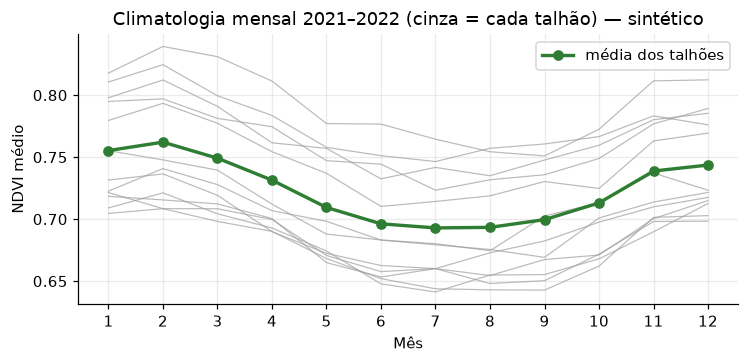

Amplitude sazonal média (máx−mín da média dos talhões): 0.069


In [5]:
clim = ts_lib.climatology(serie, "ndvi", baseline=BASE)
agg = clim.groupby("mes_ano")["clim_mean"].agg(["mean", "min", "max"])
fig, ax = plt.subplots(figsize=(7, 3.4))
for tid, g in clim.groupby("talhao_id"):
    ax.plot(g["mes_ano"], g["clim_mean"], color="#9e9e9e", lw=.8, alpha=.7)
ax.plot(agg.index, agg["mean"], "-o", color="#2e7d32", lw=2.2, label="média dos talhões")
ax.set_xticks(range(1, 13)); ax.set(xlabel="Mês", ylabel="NDVI médio", title="Climatologia mensal 2021–2022 (cinza = cada talhão) — sintético"); ax.legend()
plt.tight_layout(); plt.savefig(OUTPUTS / "figures" / "04_climatologia.png"); plt.show()
print(f"Amplitude sazonal média (máx−mín da média dos talhões): {(agg['mean'].max() - agg['mean'].min()):.3f}")

**Como ler:** a curva verde grossa é o ciclo anual médio; as cinzas são talhões individuais (diferem em nível, não em forma — efeito do gerador). Uma amplitude pequena em relação ao ruído torna difícil separar sinal de variação aleatória.

## 4. Anomalia temporal (contra a climatologia do próprio talhão)

`anom = NDVI − média(mês do ano, talhão)` e `z = anom / desvio(mês do ano, talhão)`. Resposta à pergunta: "este talhão está fora do seu normal *para esta época*?". **Depende do período-base**: se o base contém o evento, ele "normaliza" a anomalia — por isso usamos 2021–2022.

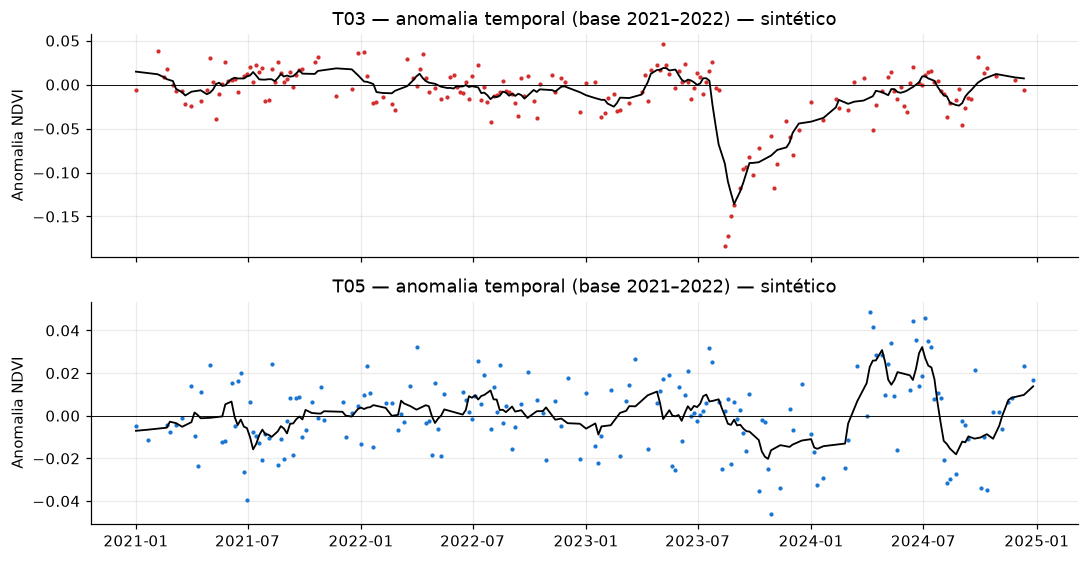

In [6]:
at = ts_lib.temporal_anomaly(serie, "ndvi", baseline=BASE)
fig, axs = plt.subplots(2, 1, figsize=(10, 5.2), sharex=True)
for ax, tid, cor in zip(axs, ["T03", "T05"], ["#d32f2f", "#1976d2"]):
    g = at[at.talhao_id == tid].dropna(subset=["anom"])
    ax.plot(g["date"], g["anom"], ".", ms=3.5, color=cor)
    ax.plot(g["date"], g["anom"].rolling(7, center=True, min_periods=3).mean(), "-", color="k", lw=1.2)
    ax.axhline(0, color="k", lw=.6); ax.set(ylabel="Anomalia NDVI", title=f"{tid} — anomalia temporal (base 2021–2022) — sintético")
plt.tight_layout(); plt.savefig(OUTPUTS / "figures" / "04_anomalia_temporal.png"); plt.show()

**Como ler:** pontos = anomalia por data, linha preta = média móvel de 7 observações. T03 (evento injetado em ago/2023) mostra queda e recuperação; T05 (sem evento) oscila em torno de 0. *Comparar com um talhão de controle evita confundir evento com mudança regional.*

## 5. Anomalia relativa (contra os vizinhos)

`anom_rel = NDVI(talhão, data) − mediana(NDVI de todos os talhões, data)` depois de remover a média de cada talhão no período-base. Remove efeitos **comuns** (atmosfera, clima, sazonalidade) e *diferenças permanentes de nível* (cultivar, idade, solo). O que sobra é **mudança diferencial** do talhão.

⚠️ Se a maioria dos talhões muda ao mesmo tempo (ex.: geada regional), a anomalia relativa **não** a enxerga — por isso use junto com a anomalia temporal.

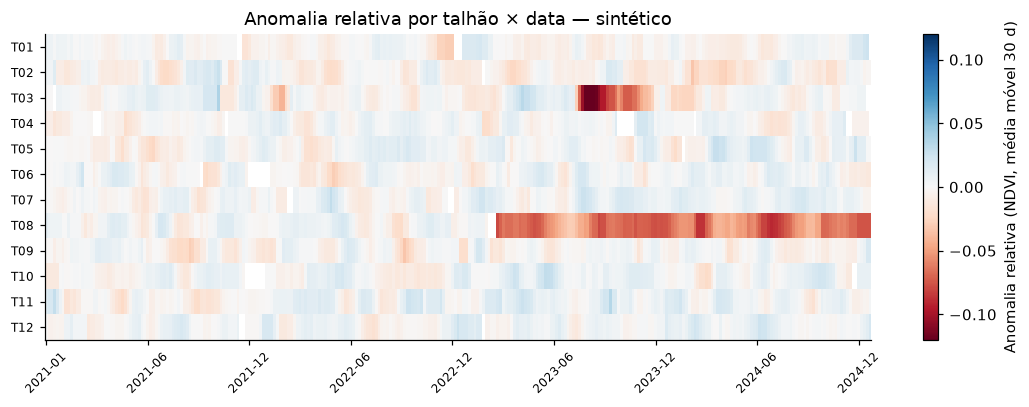

In [7]:
rel = ts_lib.relative_anomaly(serie, "ndvi", window_days=30, baseline=BASE)
piv = rel.pivot(index="talhao_id", columns="date", values="anom_rel")
fig, ax = plt.subplots(figsize=(10, 3.8))
im = ax.imshow(piv.values, aspect="auto", cmap="RdBu", vmin=-0.12, vmax=0.12, interpolation="nearest")
ticks = np.arange(0, piv.shape[1], 36); ax.set_xticks(ticks); ax.set_xticklabels([piv.columns[i].strftime("%Y-%m") for i in ticks], rotation=45, fontsize=8)
ax.set_yticks(range(len(piv))); ax.set_yticklabels(piv.index, fontsize=8); ax.grid(False)
plt.colorbar(im, label="Anomalia relativa (NDVI, média móvel 30 d)")
ax.set_title("Anomalia relativa por talhão × data — sintético")
plt.tight_layout(); plt.savefig(OUTPUTS / "figures" / "04_anomalia_relativa.png"); plt.show()

**Como ler:** azul = acima da mediana dos vizinhos, vermelho = abaixo (escala RdBu: vermelho = negativo). Procure **faixas horizontais vermelhas**: T03 deve ficar vermelho após ago/2023 e T08 após mar/2023, porque foi o que injetamos.

## 6. Marcação de anomalias e conferência com o gabarito sintético

`flag_anomalies` usa z robusto (mediana/MAD) por talhão: |z| > 3. Como a série tem lacunas e a média móvel correlaciona vizinhos, esse limiar é **uma escolha, não um padrão universal**.

Atenção a um viés: o z robusto é calculado sobre a série completa do talhão; quando a anomalia persiste por muito tempo (como T08), ela vira "o normal" para a mediana/MAD e o z pode ficar baixo. Por isso olhamos também a **média da anomalia relativa** no período pós-base.

In [8]:
fl = ts_lib.flag_anomalies(rel, z_thr=3.0).dropna(subset=["anom_rel"])
pos = rel[rel.date >= "2023-04-01"].groupby("talhao_id")["anom_rel"].mean().sort_values()
resumo = (fl.groupby("talhao_id").agg(dias_marcados=("flag", "sum"), z_min=("z_rel", "min"))
            .join(pos.rename("anom_rel_media_pos_abr2023")).sort_values("anom_rel_media_pos_abr2023"))
resumo.round(3)

,dias_marcados,z_min,anom_rel_media_pos_abr2023
talhao_id,,,
T08,0,-2.040,-0.062
T03,25,-12.809,-0.017
T02,1,-2.379,-0.008
T01,8,-3.696,-0.002
T09,3,-3.683,-0.001
T04,0,-2.937,0.002
T06,2,-3.386,0.003
T05,0,-2.203,0.004
T12,0,-2.689,0.005


In [9]:
gabarito = {"T03", "T08"}
# Duas regras complementares, definidas ANTES de olhar o gabarito (limiares convencionais, não otimizados):
regra_persistente = set(resumo.index[resumo["anom_rel_media_pos_abr2023"] < -0.03])   # nível menor por meses
regra_transitoria = set(resumo.index[resumo["dias_marcados"] >= 5])                    # >=5 datas com |z|>3
detectados = regra_persistente | regra_transitoria
print("Gabarito (injetado)      :", sorted(gabarito))
print("Regra persistente        :", sorted(regra_persistente))
print("Regra transitória (z)    :", sorted(regra_transitoria))
print("União                    :", sorted(detectados))
print("Acertos:", sorted(gabarito & detectados), "| Falsos positivos:", sorted(detectados - gabarito), "| Perdidos:", sorted(gabarito - detectados))

Gabarito (injetado)      : ['T03', 'T08']
Regra persistente        : ['T08']
Regra transitória (z)    : ['T01', 'T03']
União                    : ['T01', 'T03', 'T08']
Acertos: ['T03', 'T08'] | Falsos positivos: ['T01'] | Perdidos: []


**Interpretação:** nenhuma regra isolada serve para os dois tipos de evento. A regra *persistente* (média por meses) captura T08, mas dilui o T03, cuja queda se recupera; o z robusto captura o T03, mas "normaliza" o T08, porque a anomalia persistente vira o novo normal da série. A união recupera os dois, ao custo de um falso positivo (ruído do talhão T01 ultrapassa |z|>3 em algumas datas) — o trade-off sensibilidade × falsos alarmes. Subir o limiar de dias eliminaria esse falso positivo, mas escolher o limiar **olhando o gabarito** seria ajuste ao teste (overfitting). Esta conferência só é possível porque o dado é sintético; resultados dependem dos limiares, da janela (30 d), do ruído simulado e da semente — é um **teste de sanidade do método**, não uma medida de desempenho em campo. Com dados reais, a validação precisa de **observações de campo** (visitas, laudos, registros de manejo).